# Trajectory planning around obstacles

**Adapted from**: Joey Huchette's SIAM Optimization 2017 talk,
[Mixed-Integer Sum of Squares Optimization: Computation and Application](https://docs.google.com/presentation/d/1ASfjB1TdLJmYxT0b6rnyGh9eLbMc-66bTOt3_3yvc90/edit).
We use a compact slalom with two obstacles to illustrate the formulation.

We plan a smooth trajectory for a circular vehicle. Binary variables choose
a safe chamber for each time interval, and sum-of-squares constraints keep
the trajectory in that chamber for the **entire** interval. In particular,
collision avoidance does not rely on a time discretization.

In [1]:
using SumOfSquares
using DynamicPolynomials
using LinearAlgebra

## Geometry

The workspace is `[0, 12] × [0, 8]`. Two walls force the vehicle to go
above the first obstacle and below the second. The free space is covered
by five overlapping rectangular chambers.

In [2]:
struct Box
    xl::Float64
    yl::Float64
    xu::Float64
    yu::Float64
end

obstacles = [Box(3, 0, 5, 5), Box(7, 3, 9, 8)]
boxes = [
    Box(0, 0, 3, 8),
    Box(0, 5, 7, 8),
    Box(5, 0, 7, 8),
    Box(5, 0, 12, 3),
    Box(9, 0, 12, 8),
]
start = [1.0, 1.0]
goal = [11.0, 7.0]

2-element Vector{Float64}:
 11.0
  7.0

Shrinking each chamber by the vehicle radius ensures that the whole
vehicle fits in the original chamber when its center lies in the smaller
chamber. The overlaps allow smooth transitions between chambers.

In [3]:
vehicle_radius = 0.2
safe_boxes = [
    Box(
        b.xl + vehicle_radius,
        b.yl + vehicle_radius,
        b.xu - vehicle_radius,
        b.yu - vehicle_radius,
    ) for b in boxes
]

function in_box(point, box; atol = 0.0)
    return box.xl - atol ≤ point[1] ≤ box.xu + atol &&
           box.yl - atol ≤ point[2] ≤ box.yu + atol
end

in_box (generic function with 1 method)

## Mixed-integer SOS model

Pajarito combines a mixed-integer linear solver with a continuous conic
solver. Here we use HiGHS for the integer decisions and Clarabel for the
semidefinite and second-order cone subproblems.

In [4]:
import Pajarito, HiGHS, Clarabel
solver = optimizer_with_attributes(
    Pajarito.Optimizer,
    "oa_solver" => optimizer_with_attributes(
        HiGHS.Optimizer,
        MOI.Silent() => true,
        "mip_rel_gap" => 1e-6,
    ),
    "conic_solver" =>
        optimizer_with_attributes(Clarabel.Optimizer, MOI.Silent() => true),
    "time_limit" => 120.0,
    "tol_rel_gap" => 1e-4,
)
model = SOSModel(solver)

A JuMP Model
├ solver: Pajarito
├ objective_sense: FEASIBILITY_SENSE
├ num_variables: 0
├ num_constraints: 0
└ Names registered in the model: none

We use six one-second intervals and a quintic polynomial for each
coordinate on each interval. Every segment uses a local time `t ∈ [0, 1]`,
which avoids high powers of the global time. The same construction can
be used with higher-degree polynomials by also increasing the quadrature
order in the objective below.

In [5]:
N = 6
trajectory_degree = 5
@polyvar t
interval = @set t * (1 - t) ≥ 0
@variable(model, p[1:2, 1:N], Poly(monomials([t], 0:trajectory_degree)))
@variable(model, H[1:N, 1:length(boxes)], Bin)

6×5 Matrix{VariableRef}:
 H[1,1]  H[1,2]  H[1,3]  H[1,4]  H[1,5]
 H[2,1]  H[2,2]  H[2,3]  H[2,4]  H[2,5]
 H[3,1]  H[3,2]  H[3,3]  H[3,4]  H[3,5]
 H[4,1]  H[4,2]  H[4,3]  H[4,4]  H[4,5]
 H[5,1]  H[5,2]  H[5,3]  H[5,4]  H[5,5]
 H[6,1]  H[6,2]  H[6,3]  H[6,4]  H[6,5]

Exactly one chamber is selected on each interval. The following big-M
constraints reduce to the selected chamber's bounds when `H[j, k] = 1`.
Otherwise they reduce to the workspace bounds, so the constants come
directly from the geometry. The degree-six SOS certificates are sufficient
for these quintic univariate bounds on the interval.

In [6]:
for j in 1:N
    @constraint(model, sum(H[j, :]) == 1)
    for (k, box) in enumerate(safe_boxes)
        lower = (box.xl, box.yl)
        upper = (box.xu, box.yu)
        workspace_upper = (12, 8)
        for axis in 1:2
            @constraint(
                model,
                p[axis, j] ≥ lower[axis] * H[j, k],
                domain = interval,
                maxdegree = trajectory_degree + 1
            )
            @constraint(
                model,
                p[axis, j] ≤
                workspace_upper[axis] +
                (upper[axis] - workspace_upper[axis]) * H[j, k],
                domain = interval,
                maxdegree = trajectory_degree + 1
            )
        end
    end
end

The vehicle starts and finishes at rest, with zero acceleration. Matching
position, velocity, and acceleration at every junction makes the complete
trajectory twice continuously differentiable.

In [7]:
velocity = differentiate.(p, t)
acceleration = differentiate.(velocity, t)
jerk = differentiate.(acceleration, t)
for (order, derivative) in enumerate((p, velocity, acceleration)), axis in 1:2
    @constraint(
        model,
        derivative[axis, 1](t => 0) == (order == 1 ? start[axis] : 0)
    )
    @constraint(
        model,
        derivative[axis, N](t => 1) == (order == 1 ? goal[axis] : 0)
    )
    for j in 1:(N-1)
        @constraint(
            model,
            derivative[axis, j](t => 1) == derivative[axis, j+1](t => 0)
        )
    end
end

Two consecutive chambers must overlap. These redundant linear constraints
help the integer solver rule out impossible transitions before solving an
SDP. Similarly, the first and last chamber must contain the endpoints.

In [8]:
compatible = [
    max(a.xl, b.xl) ≤ min(a.xu, b.xu) && max(a.yl, b.yl) ≤ min(a.yu, b.yu)
    for a in safe_boxes, b in safe_boxes
]
for k in eachindex(safe_boxes)
    if !in_box(start, safe_boxes[k])
        fix(H[1, k], 0; force = true)
    end
    if !in_box(goal, safe_boxes[k])
        fix(H[N, k], 0; force = true)
    end
    for j in 1:(N-1)
        @constraint(
            model,
            H[j, k] ≤
            sum(H[j+1, l] for l in eachindex(safe_boxes) if compatible[k, l])
        )
    end
end

## Minimum-jerk objective

We minimize the integral of squared jerk, a common measure of trajectory
smoothness. The jerk of a quintic is quadratic, so three-point
Gauss-Legendre quadrature integrates its square **exactly**. These points
are only used for the objective; collision avoidance is still continuous.
Dividing jerk by the workspace width improves numerical scaling without
changing the minimizing trajectory.

In [9]:
nodes = [(1 - sqrt(3 / 5)) / 2, 0.5, (1 + sqrt(3 / 5)) / 2]
weights = [5 / 18, 4 / 9, 5 / 18]
weighted_jerk = [
    sqrt(weight) / 12 * jerk[axis, j](t => node) for
    axis in 1:2, j in 1:N, (node, weight) in zip(nodes, weights)
]

2×6×3 Array{AffExpr, 3}:
[:, :, 1] =
 0.26352313834736496 _[4] + 0.11879798623086686 _[5] + 0.03347182722980223 _[6]     …  0.26352313834736496 _[64] + 0.11879798623086686 _[65] + 0.03347182722980223 _[66]
 0.26352313834736496 _[10] + 0.11879798623086686 _[11] + 0.03347182722980223 _[12]     0.26352313834736496 _[70] + 0.11879798623086686 _[71] + 0.03347182722980223 _[72]

[:, :, 2] =
 0.3333333333333333 _[4] + 0.6666666666666666 _[5] + 0.8333333333333333 _[6]     …  0.3333333333333333 _[64] + 0.6666666666666666 _[65] + 0.8333333333333333 _[66]
 0.3333333333333333 _[10] + 0.6666666666666666 _[11] + 0.8333333333333333 _[12]     0.3333333333333333 _[70] + 0.6666666666666666 _[71] + 0.8333333333333333 _[72]

[:, :, 3] =
 0.26352313834736496 _[4] + 0.9352945671585929 _[5] + 2.0747132795491177 _[6]     …  0.26352313834736496 _[64] + 0.9352945671585929 _[65] + 2.0747132795491177 _[66]
 0.26352313834736496 _[10] + 0.9352945671585929 _[11] + 2.0747132795491177 _[12]     0.26352313834736496 _[7

A rotated second-order cone bounds the sum of squared weighted jerk
values by `jerk_cost`.

In [10]:
@variable(model, jerk_cost ≥ 0)
@constraint(
    model,
    [jerk_cost / 2; 1; vec(weighted_jerk)] in RotatedSecondOrderCone()
)
@objective(model, Min, jerk_cost)
optimize!(model)
solution_summary(model)

solving continuous relaxation
continuous relaxation status is OPTIMAL
separated 0 rays before imposing integrality
 iter     cuts          obj        bound          gap
continuous subproblem status is OPTIMAL
    1     3923   1.1793e+01   5.8345e+00   5.0528e-01
┌ Warning: integral solution repeated
└ @ Pajarito ~/.julia/packages/Pajarito/mhMdw/src/algorithms.jl:103
separation cuts could not be added
    2     3923   1.1793e+01   1.1793e+01   0.0000e+00
objective relative gap 0.0 reached; terminating
OA solver finished with status OPTIMAL, after 9.260895013809204 seconds and 3923 cuts
iterative method used 2 iterations



solution_summary(; result = 1, verbose = false)
├ solver_name          : Pajarito
├ Termination
│ ├ termination_status : OPTIMAL
│ ├ result_count       : 1
│ ├ raw_status         : OPTIMAL
│ └ objective_bound    : 1.17935e+01
├ Solution (result = 1)
│ ├ primal_status        : FEASIBLE_POINT
│ ├ dual_status          : NO_SOLUTION
│ ├ objective_value      : 1.17935e+01
│ └ relative_gap         : 0.00000e+00
└ Work counters
  ├ solve_time (sec)   : 9.26090e+00
  └ node_count         : 1

The chosen chambers and the polynomial coefficients are obtained as follows.

In [11]:
selection = [argmax(value.(H[j, :])) for j in 1:N]
position_opt = value.(p)
velocity_opt = value.(velocity)
acceleration_opt = value.(acceleration)
selection

6-element Vector{Int64}:
 1
 1
 2
 3
 4
 5

We check the endpoints, the junctions, and the selected chamber bounds.
Sampling here is a numerical check of the returned solution, in addition
to the SOS constraints imposed on the whole interval.

## Visualization

The left panel shows the path and the selected safe chamber. The circular
marker has the same radius as the vehicle in the model. The right panels
show the speed and acceleration, which remain continuous across segment
boundaries.

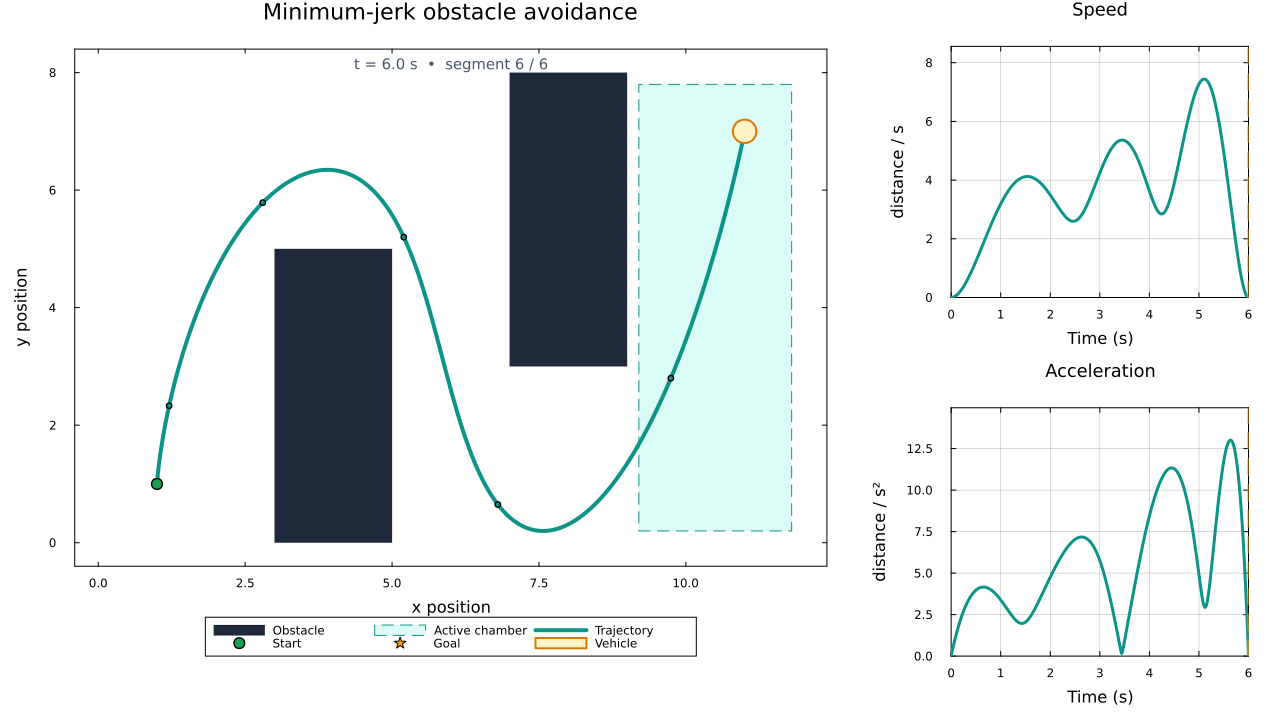

In [12]:
import Plots

function evaluate_trajectory(polynomials, time)
    segment = min(floor(Int, time) + 1, N)
    local_time = time - segment + 1
    return [q(t => local_time) for q in polynomials[:, segment]]
end

sample_times = range(0, N; length = 601)
path =
    hcat([evaluate_trajectory(position_opt, time) for time in sample_times]...)
speeds =
    [norm(evaluate_trajectory(velocity_opt, time)) for time in sample_times]
accelerations =
    [norm(evaluate_trajectory(acceleration_opt, time)) for time in sample_times]

function box_shape(box)
    return Plots.Shape(
        [box.xl, box.xu, box.xu, box.xl],
        [box.yl, box.yl, box.yu, box.yu],
    )
end

function motion_profile(values, time, title, unit)
    plot = Plots.plot(
        sample_times,
        values;
        color = "#cbd5e1",
        linewidth = 2,
        label = false,
        title = title,
        xlabel = "Time (s)",
        ylabel = unit,
        xlims = (0, N),
        ylims = (0, 1.15 * maximum(values)),
        gridalpha = 0.15,
        framestyle = :box,
        titlefontsize = 12,
    )
    past = sample_times .≤ time
    Plots.plot!(
        plot,
        sample_times[past],
        values[past];
        color = "#0d9488",
        linewidth = 3,
        label = false,
    )
    Plots.vline!(
        plot,
        [time];
        color = "#f59e0b",
        linewidth = 2,
        linestyle = :dash,
        label = false,
    )
    return plot
end

function trajectory_figure(time = N)
    segment = min(floor(Int, time) + 1, N)
    scene = Plots.plot(;
        xlims = (-0.4, 12.4),
        ylims = (-0.4, 8.4),
        aspect_ratio = :equal,
        xlabel = "x position",
        ylabel = "y position",
        title = "Minimum-jerk obstacle avoidance",
        titlefontsize = 15,
        grid = false,
        framestyle = :box,
        legend = :outerbottom,
        legend_columns = 3,
    )
    for (i, obstacle) in enumerate(obstacles)
        Plots.plot!(
            scene,
            box_shape(obstacle);
            color = "#1e293b",
            linewidth = 0,
            label = i == 1 ? "Obstacle" : false,
        )
    end
    Plots.plot!(
        scene,
        box_shape(safe_boxes[selection[segment]]);
        fillcolor = "#99f6e4",
        fillalpha = 0.35,
        linecolor = "#0d9488",
        linestyle = :dash,
        label = "Active chamber",
    )
    Plots.plot!(
        scene,
        path[1, :],
        path[2, :];
        color = "#cbd5e1",
        linewidth = 2,
        linestyle = :dash,
        label = false,
    )
    past = sample_times .≤ time
    Plots.plot!(
        scene,
        path[1, past],
        path[2, past];
        color = "#0d9488",
        linewidth = 4,
        label = "Trajectory",
    )
    junctions = hcat([evaluate_trajectory(position_opt, j) for j in 0:N]...)
    Plots.scatter!(
        scene,
        junctions[1, :],
        junctions[2, :];
        color = "#0d9488",
        markersize = 3,
        label = false,
    )
    Plots.scatter!(
        scene,
        [start[1]],
        [start[2]];
        color = "#16a34a",
        markersize = 6,
        label = "Start",
    )
    Plots.scatter!(
        scene,
        [goal[1]],
        [goal[2]];
        color = "#f59e0b",
        marker = :star5,
        markersize = 9,
        label = "Goal",
    )
    point = evaluate_trajectory(position_opt, time)
    angles = range(0, 2π; length = 40)
    vehicle = Plots.Shape(
        point[1] .+ vehicle_radius .* cos.(angles),
        point[2] .+ vehicle_radius .* sin.(angles),
    )
    Plots.plot!(
        scene,
        vehicle;
        fillcolor = "#fef3c7",
        linecolor = "#d97706",
        linewidth = 2,
        label = "Vehicle",
    )
    Plots.annotate!(
        scene,
        6,
        8.15,
        Plots.text(
            "t = $(round(time; digits = 2)) s  •  segment $segment / $N",
            10,
            "#475569",
        ),
    )
    speed = motion_profile(speeds, time, "Speed", "distance / s")
    acceleration =
        motion_profile(accelerations, time, "Acceleration", "distance / s²")
    layout = Plots.@layout [a{0.72w} [b; c]]
    return Plots.plot(
        scene,
        speed,
        acceleration;
        layout = layout,
        size = (1280, 720),
        margin = 6 * Plots.mm,
        background_color = :white,
    )
end

figure = trajectory_figure()
Plots.savefig(figure, "obstacles.png")
figure

## Animation and video

Plots records frames of the same figure as the vehicle follows the solved
trajectory. At 20 frames per second this plays back in real time. Both
formats use the same frames: an MP4 for sharing and an animated GIF that
can be displayed directly in a notebook or this tutorial.

[ Info: Saved animation to /home/runner/work/SumOfSquares.jl/SumOfSquares.jl/docs/src/generated/Systems and Control/obstacles.mp4
[ Info: Saved animation to /home/runner/work/SumOfSquares.jl/SumOfSquares.jl/docs/src/generated/Systems and Control/obstacles.gif


Plots.AnimatedGif("/home/runner/work/SumOfSquares.jl/SumOfSquares.jl/docs/src/generated/Systems and Control/obstacles.gif")
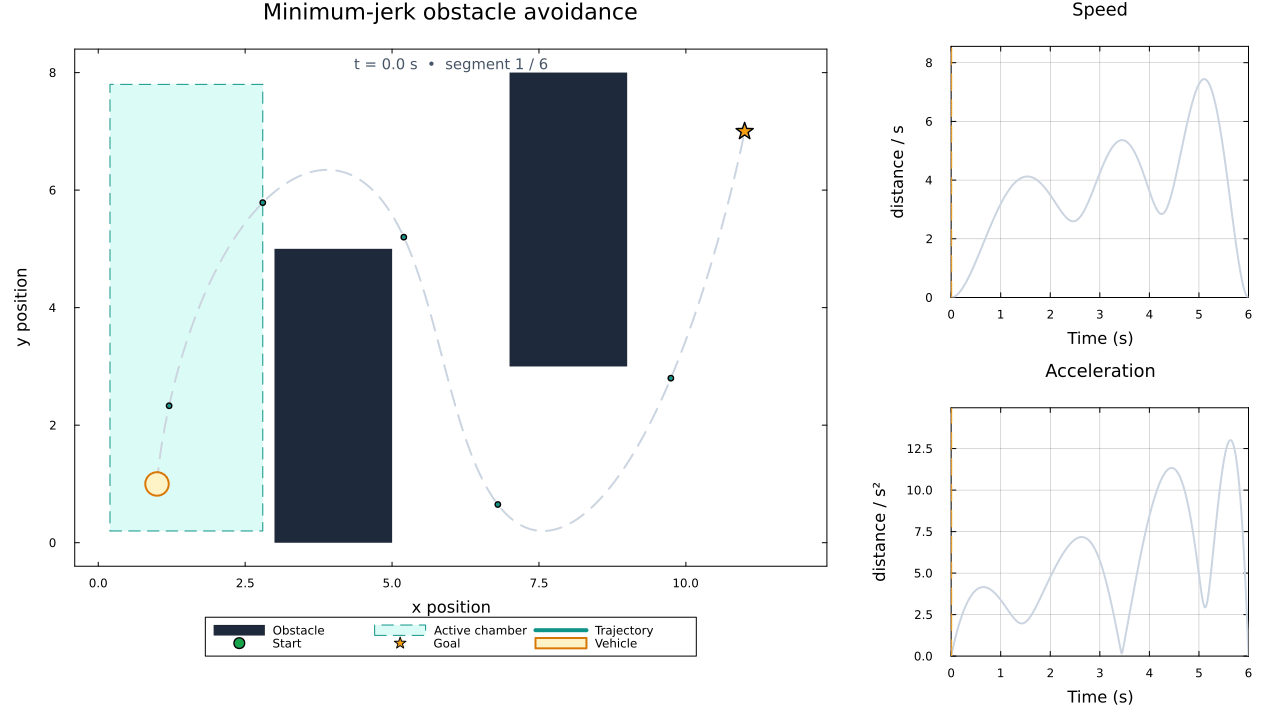

In [13]:
animation = Plots.@animate for time in range(0, N; length = 20N + 1)
    trajectory_figure(time)
end
Plots.mp4(animation, "obstacles.mp4"; fps = 20);
Plots.gif(animation, "obstacles.gif"; fps = 20)

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*